In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

### Get data

In [9]:
sin_theta_i = np.array([8, 17, 23, 25, 29, 36,  14, 19, 31, 33])  # esempio
sin_theta_r = np.array([4, 11, 14, 15, 18, 21,  10, 12, 22, 23])  # esempio

In [10]:
sigma_i = np.full(len(sin_theta_i), 2)
sigma_r = np.full(len(sin_theta_i), 2)

### Fit

Modello lineare: sin(theta_i) = n * sin(theta_r)  
so y= sin(theta_i), x= sin(theta_r)
need to find best param for n
rem that fit must have the thing i want as a param, not as the think i'm searching

In [11]:
def snell_model(x, n):
    return n * x

In [12]:
popt, pcov = curve_fit(snell_model, sin_theta_r, sin_theta_i, sigma=sigma_r)
n_plexiglass = popt[0]
err_plexiglass = np.sqrt(pcov[0, 0])  # errors are the roots of stuff on the digonal of pcov
print(f"Indice di rifrazione stimato: n = {n_plexiglass:.3f}+{err_plexiglass:.3f}")

Indice di rifrazione stimato: n = 1.552+0.042


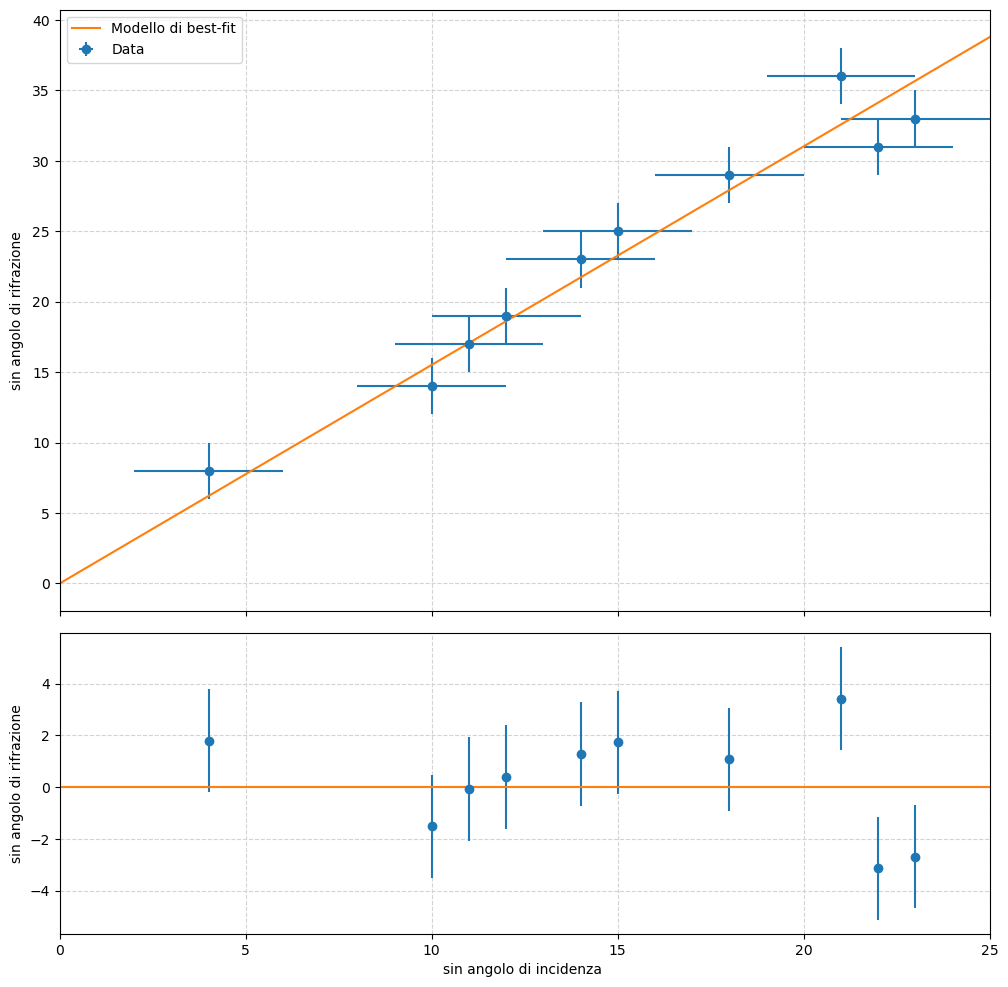

In [13]:
# x, y, sigma_x, sigma_y
# have popt, pcov

x = sin_theta_r
y = sin_theta_i
sigma_x = sigma_r
sigma_y = sigma_i


res = y - snell_model(x, *popt)

# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
xgrid = np.linspace(0.0, 25.0, 100)
ax1.plot(xgrid, snell_model(xgrid, *popt), label='Modello di best-fit')

# Setup the axes, grids and legend.
ax1.set_ylabel('sin angolo di rifrazione')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# Setup the axes, grids and legend.
ax2.set_xlabel('sin angolo di incidenza ')
ax2.set_ylabel('sin angolo di rifrazione')
ax2.grid(color='lightgray', ls='dashed')

# The final touch to main canvas
plt.xlim(0.0, 25.0)
fig.align_ylabels((ax1, ax2))

plt.show()